In [1]:
%load_ext autoreload
%autoreload 2

In [7]:
import os
import torch.backends.cudnn as cudnn
import torch
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import cv2

#from pytorch_grad_cam import GradCAM
#from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
#from pytorch_grad_cam.utils.image import show_cam_on_image
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz



sys.path.append('../../MARS')
sys.path.append('../../MARS/run_lars/code_3d')


#from MARS.run_lars.code_3d.dataset import get_datasets, dataset_center
from MARS.run_lars.code_3d.utils import model_prediction, my_model, modify_resnet_to_accomodate_two_channels

from MARS.run_lars.code_3d.dataset import dataset_3d, dataset_3d_center, get_datasets_3d
import h5py
import nibabel as nib
from totalsegmentator.python_api import totalsegmentator

In [8]:
#data_path = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_bone_segmentation/train_df_with_ct_bone_segmentation.csv'
data_path = '/gpfs/data/mayerhoeferlab/projects/myeloma/datafiles_for_mars/dfs_with_aligned_ct/val_df_with_aligned_ct.csv'
data_path_img = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5'

In [41]:
ds = get_datasets_3d('val', None, None, False, data_path_img, data_path,
                     6.4, None, None, 'PET_jco', ct_mode = 'CT', ct_clip_threshold_low = -500, ct_clip_threshold_high = 1300)


In [43]:
ds[3][0][1,:,:,:].min()

tensor(-1024.)

In [ ]:
xx = ds[3][0]
xx[1,0,0,5]

tensor(0.)

In [ ]:
_, superaxs = plt.subplots(1,3, figsize=(15,5))
xx = ds[3][0]

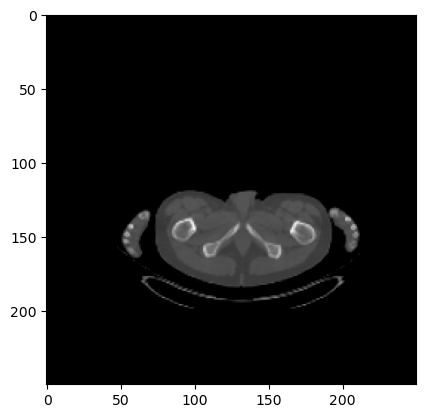

In [35]:
plt.imshow(xx[1,:,:,5], cmap='gray')

In [ ]:
#fig, axs = plt.subplots(2, 1, figsize=(5, 10 ))
#axs[0].imshow(xx[0, :,:,150], cmap='gray')
xx = ds[3][0]
superaxs[0].imshow(xx[1, :,:,150], cmap='gray')

In [77]:
xx = ds[3][0]
superaxs[1].imshow(xx[1, :,:,150], cmap='gray')

[1.24551376 1.24551376 0.91743119]
[1.24551376 1.24551376 0.91743119]


In [78]:
xx = ds[3][0]
superaxs[2].imshow(xx[1, :,:,150], cmap='gray')

[1.24551376 1.24551376 0.91743119]
[1.24551376 1.24551376 0.91743119]


In [73]:
xx.shape

torch.Size([2, 250, 250, 300])

In [79]:
# get current figure of superaxs
# save superaxs figure
superaxs[0].get_figure().savefig('/gpfs/home/kn2347/MARS/ct_seg_test_with_viz_3D.png')

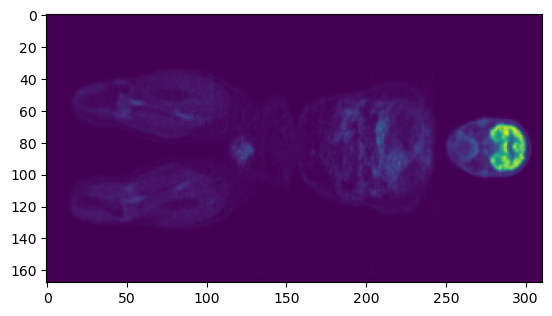

In [58]:
asdf = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/ct_bone_segmentations/5445069/5445069_ct_3_bone_segmentation.h5'
# open as h5
with h5py.File(asdf, 'r') as f:
    bone_seg = f['segmentation'][:]

pt_f = '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/images_h5/5445069/5445069_pt_2.h5'
with h5py.File(pt_f, 'r') as f:
    pt = f['image'][:]

plt.imshow(pt[70,:,:])

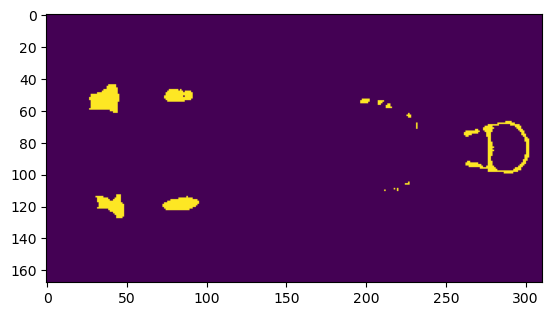

In [59]:
plt.imshow(bone_seg[70,:,:])

In [22]:
img = xx[1,:,:,:].cpu().numpy()

In [63]:
img = xx[1,:,:,:].cpu().numpy()
img2 = xx[0,:,:,:].cpu().numpy()

# make gif of all slices using img

import imageio
images = []

normed = (img - img.min()) / (img.max() - img.min()) * 255
normed = normed.astype(np.uint8)

normed2 = (img2 - img2.min()) / (img2.max() - img2.min()) * 255
normed2 = 255 - normed2
normed2 = normed2.astype(np.uint8)

for i in range(img.shape[0]):
    slice_img = normed[i,:,:]
    slice_img2 = normed2[i,:,:]
    # put side by side
    slice_img = np.concatenate((slice_img2, slice_img), axis=1)
    images.append(slice_img)
imageio.mimsave('/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/ct_segmentation_slices.gif', images, fps=5)